<a href="https://colab.research.google.com/github/kuroshkarimi/Machine-Learning-and-Data-Analysis/blob/main/Deep_Learning/Predicting_income_category.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting income category

The task is to develop a binary classification model that predicts whether a person’s annual income exceeds 50,000 dollars, using the Adult dataset, downloaded through scikit-learn’s OpenML interface. This project focuses on preparing numerical and categorical features, training a neural network, and comparing its performance with logistic regression.
Each row represents one person. Input features include the followings:

| Column | Meaning |
|---|---|
| **status** | **marital-status**: married, divorced, never married, widowed, etc. |
| **occupation** | Job category, such as sales, technical support, or managerial work. |
| **relationship** | Household or family role, such as husband, wife, own child, or other relative. |
| **race** | Recorded racial category. |
| **sex** | Recorded sex; the original dataset uses Female and Male. |
| **capital-gain** | Reported monetary gains from selling capital assets, such as investments. |
| **capital-loss** | Reported monetary losses from selling capital assets. |
| **hours-per-week** | Number of hours worked per week. |
| **native-country** | Country of origin, generally interpreted as country of birth. |
| **age** | Person’s age in years. |
| **workclass** | Employment category, such as private-sector, government, or self-employed. |
| **fnlwgt** | “Final weight”: a survey weight indicating how many people in the population the record represents. It is not income. |
| **education** | Highest recorded education level, such as high-school graduate, bachelor’s, or master’s. |
| **education-num** | An ordered numerical code for education level. It should not automatically be interpreted as years spent in education. |

The target is:
- 0: Annual income is at or below 50,000 dollars.
- 1: Annual income is above $50,000.

For each person, the model should produce an estimated probability of belonging to class 1. A chosen threshold then converts that score into a predicted income category.
Your implementation should accomplish the following:
1. Explore the dataset: examine feature types, missing values, class proportions, and relationships between features and income category.
2. Split the data: allocate 60% for training, 20% for validation, and 20% for testing, preserving approximately the same class proportions.
3. Prepare the inputs: impute missing numerical values, standardize numerical features, and one-hot encode categorical features. Fit preprocessing exclusively on the training set.
4. Establish a baseline: train logistic regression using the prepared features.
5. Train a decent neural network
6. Select the model: compare validation average precision, validation log-loss, and training time.
7. Evaluate the final model: report test average precision, log-loss, ROC AUC, precision, recall and F1 with the threshold value of 0.5.
8. Demonstrate prediction: pass a raw observation through the fitted preprocessing steps and obtain its predicted probability and category.
The main research question is:
Does a dense neural network improve income classification enough to justify its additional complexity compared with logistic regression?

A successful project does not require the neural network to win. It requires a fair comparison, preprocessing without data leakage, and a clear explanation of the results.
The final deliverable should be a notebook containing the analysis, preprocessing, training, evaluation, and conclusions. Because the dataset is historical, interpret the results as performance on this dataset—not evidence that the model reliably predicts present-day incomes.

In [47]:
# Importing required libraries

import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    average_precision_score,
    roc_auc_score,
    classification_report
)

In [48]:
# Loading the data

adult = fetch_openml(
    name='adult',
    version=2,
    as_frame=True,

)
x = adult.data.copy()
target = adult.target.copy()

In [49]:
print(x.head(2))
print("\n")
print(target.head(2))

   age workclass  fnlwgt education  education-num      marital-status  \
0   25   Private  226802      11th              7       Never-married   
1   38   Private   89814   HS-grad              9  Married-civ-spouse   

          occupation relationship   race   sex  capital-gain  capital-loss  \
0  Machine-op-inspct    Own-child  Black  Male             0             0   
1    Farming-fishing      Husband  White  Male             0             0   

   hours-per-week native-country  
0              40  United-States  
1              50  United-States  


0    <=50K
1    <=50K
Name: class, dtype: category
Categories (2, object): ['<=50K', '>50K']


In [50]:
# Checking some general properties of the data including the number of NaNs for each column

x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
dtypes: category(8), int64(6)
memory usage: 2.6 MB


In [51]:
# Statistical properties of the data

x.describe(include = 'all')

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
count,48842.000000,46043,4.884200e+04,48842,48842.000000,48842,46033,48842,48842,48842,48842.000000,48842.000000,48842.000000,47985
unique,NaN,8,NaN,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States
freq,NaN,33906,NaN,15784,NaN,22379,6172,19716,41762,32650,NaN,NaN,NaN,43832
mean,38.643585,NaN,1.896641e+05,NaN,10.078089,NaN,NaN,NaN,NaN,NaN,1079.067626,87.502314,40.422382,NaN
std,13.710510,NaN,1.056040e+05,NaN,2.570973,NaN,NaN,NaN,NaN,NaN,7452.019058,403.004552,12.391444,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN
25%,28.000000,NaN,1.175505e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN
50%,37.000000,NaN,1.781445e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN
75%,48.000000,NaN,2.376420e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN


In [52]:
# Checking the target column

target.info()

<class 'pandas.core.series.Series'>
RangeIndex: 48842 entries, 0 to 48841
Series name: class
Non-Null Count  Dtype   
--------------  -----   
48842 non-null  category
dtypes: category(1)
memory usage: 47.9 KB


In [53]:
# Evaluating the population and percentage of each label category

print(target.value_counts())
target.value_counts(normalize = True)

class
<=50K    37155
>50K     11687
Name: count, dtype: int64


,proportion
class,
<=50K,0.760718
>50K,0.239282


In [54]:
target

,class
0,<=50K
1,<=50K
2,>50K
3,>50K
4,<=50K
...,...
48837,<=50K
48838,>50K
48839,<=50K
48840,<=50K


In [55]:
# Converting the target column format to numbers

y = (target == '>50K').astype('int32')
np.unique(y, return_counts = True)

(array([0, 1], dtype=int32), array([37155, 11687]))

In [56]:
# fnlwgt is a survey weighting variable.
# We omit it from this introductory, unweighted experiment.
x = x.drop(columns=["fnlwgt"])

In [57]:
# Distinguishing the categorical and numerical columns

numeric_columns = x.select_dtypes(include = 'number').columns.tolist()
categorical_columns = x.select_dtypes(exclude = 'number').columns.tolist()
print(numeric_columns)
print(categorical_columns)

['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [58]:
# Taking a look at the unique elements of each column

for col in categorical_columns:
  print(f"{col} : {x[col].unique()}")

workclass : ['Private', 'Local-gov', NaN, 'Self-emp-not-inc', 'Federal-gov', 'State-gov', 'Self-emp-inc', 'Without-pay', 'Never-worked']
Categories (8, object): ['Federal-gov', 'Local-gov', 'Never-worked', 'Private', 'Self-emp-inc',
                         'Self-emp-not-inc', 'State-gov', 'Without-pay']
education : ['11th', 'HS-grad', 'Assoc-acdm', 'Some-college', '10th', ..., 'Assoc-voc', '9th', '12th', '1st-4th', 'Preschool']
Length: 16
Categories (16, object): ['10th', '11th', '12th', '1st-4th', ..., 'Masters', 'Preschool',
                          'Prof-school', 'Some-college']
marital-status : ['Never-married', 'Married-civ-spouse', 'Widowed', 'Divorced', 'Separated', 'Married-spouse-absent', 'Married-AF-spouse']
Categories (7, object): ['Divorced', 'Married-AF-spouse', 'Married-civ-spouse',
                         'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed']
occupation : ['Machine-op-inspct', 'Farming-fishing', 'Protective-serv', NaN, 'Other-service', ...,

In [59]:
# Splitting the data into training, validation and test sets as explained in the task

SEED = 42
x_train, x_val_test, y_train, y_val_test = train_test_split(x.iloc[:-2, :], y[:-2],
                            test_size = 0.2, stratify = y[:-2], shuffle = True, random_state = SEED)

x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test,
                           test_size = 0.5, stratify = y_val_test, shuffle = True, random_state = SEED)

print('shape of each section: \n', x_train.shape, x_val.shape, x_test.shape)
print('proportion of the training positives: ', np.mean(y_train))
print('proportion of the validation positives: ', np.mean(y_val))
print('proportion of the test positives: ', np.mean(y_test))

shape of each section: 
 (39072, 13) (4884, 13) (4884, 13)
proportion of the training positives:  0.23927620802620803
proportion of the validation positives:  0.23935298935298935
proportion of the test positives:  0.23914823914823916


In [60]:
# Creating pipelines for handling numeric and categorical columns easily

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline([  ('imputer', SimpleImputer(strategy = 'median')),
                             ('standardization', StandardScaler())  ])



categorical_pipeline = Pipeline([ ('imputer', SimpleImputer(strategy = 'constant', fill_value = 'Missing')),
                                 ('onehot', OneHotEncoder(handle_unknown = 'ignore', sparse_output = False)) ])

# sparse_output=False produces a conventional dense array for this small example.
# handle_unknown="ignore" allows an unseen category to be transformed without raising an error. Its one-hot
# strategy = 'constant' and fill_value = 'Missing' consider the constant character (Missing) instead of the nan values

In [61]:
# Doing the transformation of the columns with respect to what we set in the Pipelines

from sklearn.compose import ColumnTransformer

preprocessing = ColumnTransformer([  ('numeric', numeric_pipeline, numeric_columns),
                                  ('categorical', categorical_pipeline, categorical_columns)  ])

x_train_prepared = preprocessing.fit_transform(x_train)
x_val_prepared = preprocessing.transform(x_val)
x_test_prepared = preprocessing.transform(x_test)


# Baseline Model

In [62]:
# Defining a baseline logistic regression algorithm, fitting the model and getting the probabilities
# on the validation data

from time import time
from sklearn.linear_model import LogisticRegression

start_time = time()

baseline = LogisticRegression(max_iter = 200, random_state = SEED)
baseline.fit(x_train_prepared, y_train)

baseline_training_duration = round(time() - start_time, 3)
print('baseline training duration: \n', baseline_training_duration)
baseline_prediction_val = baseline.predict_proba(x_val_prepared)[:, 1]
baseline_prediction_test = baseline.predict_proba(x_test_prepared)[:, 1]



baseline training duration: 
 1.719


In [63]:
# Evaluating how good is the logistic regression model in ranking the positive predictions
# above the negative ones using average_precision
baseline_average_precision_val = round(average_precision_score(y_val,
                                   baseline_prediction_val), 4)
print('baseline average precision: \n', baseline_average_precision_val)



baseline average precision: 
 0.7709


In [64]:
# Calculating the roc-auc_score
baseline_roc_auc_val = round(roc_auc_score(y_val, baseline_prediction_val), 4)
print('baseline roc_auc_score_val :\n', baseline_roc_auc_val)

baseline_roc_auc_test = round(roc_auc_score(y_test, baseline_prediction_test), 4)
print('baseline roc_auc_score_test :\n', baseline_roc_auc_test)

baseline roc_auc_score_val :
 0.9076
baseline roc_auc_score_test :
 0.9043


In [65]:
# calculating the validation loss using log_loss from sklearn.metrics
from sklearn.metrics import log_loss

baseline_log_loss_val = round(log_loss(y_val, baseline_prediction_val), 4)
# Rounding using the built-in round function
print('baseline loss: \n', baseline_log_loss_val)

baseline loss: 
 0.3155


In [86]:
threshold = .05

baseline_pred_class_val = (baseline_prediction_val >= threshold).astype('int32')

print(classification_report(y_val, baseline_pred_class_val))


              precision    recall  f1-score   support

           0       0.99      0.53      0.69      3715
           1       0.40      0.98      0.56      1169

    accuracy                           0.64      4884
   macro avg       0.69      0.76      0.63      4884
weighted avg       0.85      0.64      0.66      4884



In [87]:
baseline_pred_class_test = (baseline_prediction_test >= threshold).astype('int32')

print(classification_report(y_test, baseline_pred_class_test))

              precision    recall  f1-score   support

           0       0.99      0.52      0.68      3716
           1       0.39      0.98      0.56      1168

    accuracy                           0.63      4884
   macro avg       0.69      0.75      0.62      4884
weighted avg       0.84      0.63      0.65      4884



In [89]:
# Evaluation of the roc_curve and its score for test data

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr_baseline_val, tpr_baseline_val, thresholds_val = roc_curve(y_val, baseline_prediction_val)
fpr_baseline_test, tpr_baseline_test, thresholds_test = roc_curve(y_test, baseline_prediction_test)



### Finding and Visualizing Thresholds on the ROC Curve

The `roc_curve` function returns an array of `thresholds` sorted in descending order (with an arbitrary maximum threshold added at index `0` representing "predicting everything as negative"). We can find the optimal threshold using geometric methods or by targeting specific criteria (like a desired recall rate).

In [92]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Geometric optimization: finding the threshold closest to the top-left corner (0, 1)
# This is equivalent to maximizing (True Positive Rate - False Positive Rate), also known as Youden's J statistic
distances = np.sqrt(fpr_baseline_val**2 + (1 - tpr_baseline_val)**2)
best_idx = np.argmin(distances)
best_threshold = thresholds_val[best_idx]

print(f"Best threshold (closest to top-left): {best_threshold:.4f}")
print(f"Achieved FPR: {fpr_baseline_val[best_idx]:.4f}, TPR: {tpr_baseline_val[best_idx]:.4f}\n")

# 2. Targeted Recall: finding the threshold that guarantees at least 98% True Positive Rate
target_tpr = 0.98
target_idx = np.where(tpr_baseline_val >= target_tpr)[0][0]
target_threshold = thresholds_val[target_idx]

print(f"Threshold for >= {target_tpr*100}% TPR: {target_threshold:.4f}")
print(f"Achieved FPR: {fpr_baseline_val[target_idx]:.4f}, TPR: {tpr_baseline_val[target_idx]:.4f}\n")

Best threshold (closest to top-left): 0.2636
Achieved FPR: 0.1828, TPR: 0.8204

Threshold for >= 98.0% TPR: 0.0577
Achieved FPR: 0.4458, TPR: 0.9803



# MLP model

In [94]:
x_train_prepared.shape

(39072, 107)

In [95]:
# Neural Network

import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Input, BatchNormalization, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

nn_model = Sequential([
    Input(shape = (x_train_prepared.shape[1],)),
    Dense(128, activation = 'relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(64, activation = 'relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1, activation = 'sigmoid')
])


nn_model.compile(
    loss = 'binary_crossentropy',
    optimizer = Adam(learning_rate = 0.0001),
    metrics = ['accuracy']
)

start_time = time()

HISTORY = nn_model.fit(
    x_train_prepared,
    y_train,
    batch_size = 128,
    epochs = 100,
    validation_data = (x_val_prepared, y_val),
    callbacks = [EarlyStopping(monitor="val_loss", patience = 5, restore_best_weights = True)]
)

nn_training_duration = round(time() - start_time, 3)
print('nn training duration: \n', nn_training_duration)

Epoch 1/100
306/306 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6843 - loss: 0.6288 - val_accuracy: 0.7944 - val_loss: 0.5094
Epoch 2/100
306/306 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7886 - loss: 0.4822 - val_accuracy: 0.8290 - val_loss: 0.4099
Epoch 3/100
306/306 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8162 - loss: 0.4296 - val_accuracy: 0.8456 - val_loss: 0.3711
Epoch 4/100
306/306 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8288 - loss: 0.3968 - val_accuracy: 0.8544 - val_loss: 0.3497
Epoch 5/100
306/306 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8344 - loss: 0.3785 - val_accuracy: 0.8565 - val_loss: 0.3361
Epoch 6/100
306/306 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8386 - loss: 0.3650 - val_accuracy: 0.8579 - val_loss: 0.3278
Epoch 7/100
306/306 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8400 - loss: 0.3582 - val_accuracy: 0.8583 - val_loss: 0.3222
Epoch 8/100
306/306 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8426 - loss: 0.3458 - val_ac

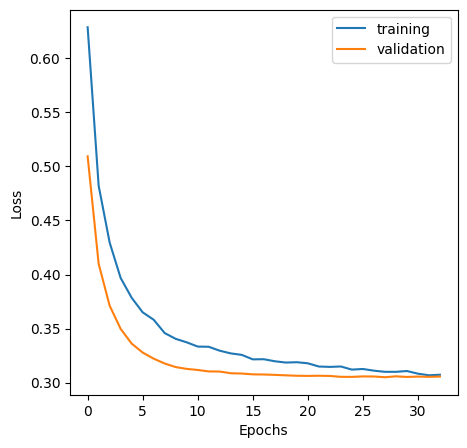

In [96]:
plt.figure(figsize = (5, 5))
plt.plot(HISTORY.history['loss'], label = 'training')
plt.plot(HISTORY.history['val_loss'], label = 'validation')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [102]:
# Evaluating how good the neural network is in ranking the positive predictions
# above the negative ones using average_precision

nn_prediction_val = nn_model.predict(x_val_prepared).ravel()
nn_prediction_test = nn_model.predict(x_test_prepared).ravel()

nn_average_precision_val = round(average_precision_score(y_val, nn_prediction_val), 3)
print('average precision belonging to neural network:\n', nn_average_precision_val)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
average precision belonging to neural network:
 0.787


In [ ]:
fpr_nn_val, tpr_nn_val, thresholds_val = roc_curve(y_val, nn_prediction_val)
fpr_nn_test, tpr_nn_test, thresholds_test = roc_curve(y_test, nn_prediction_test)

In [103]:
nn_roc_auc_val = round(roc_auc_score(y_val, nn_prediction_val), 3)

print('roc_auc_score belonging to nn model: \n', nn_roc_auc_val)

roc_auc_score belonging to nn model: 
 0.914


In [104]:
nn_log_loss_val = round(log_loss(y_val, nn_prediction_val), 3)
print('nn loss: \n', nn_log_loss_val)

nn loss: 
 0.305


In [105]:
nn_pred_class_val = (nn_prediction_val >= threshold).astype('int32')

print(classification_report(y_val, nn_pred_class_val))

              precision    recall  f1-score   support

           0       0.99      0.55      0.71      3715
           1       0.41      0.98      0.58      1169

    accuracy                           0.66      4884
   macro avg       0.70      0.77      0.64      4884
weighted avg       0.85      0.66      0.68      4884



In [107]:
nn_pred_class_test = (nn_prediction_test >= threshold).astype('int32')
print(classification_report(y_test, nn_pred_class_test))

              precision    recall  f1-score   support

           0       0.99      0.54      0.70      3716
           1       0.40      0.98      0.57      1168

    accuracy                           0.65      4884
   macro avg       0.70      0.76      0.64      4884
weighted avg       0.85      0.65      0.67      4884



In [109]:
comparison = pd.DataFrame({
    'model': ['baseline', 'neural network'],
    'average_precision': [baseline_average_precision_val, nn_average_precision_val],
    'roc_auc_score': [baseline_roc_auc_val, nn_roc_auc_val],
    'log_loss': [baseline_log_loss_val, nn_log_loss_val],
    'training_duration': [baseline_training_duration, nn_training_duration]
})

comparison

,model,average_precision,roc_auc_score,log_loss,training_duration
0,baseline,0.7709,0.9076,0.3155,1.719
1,neural network,0.7870,0.9140,0.3050,97.463


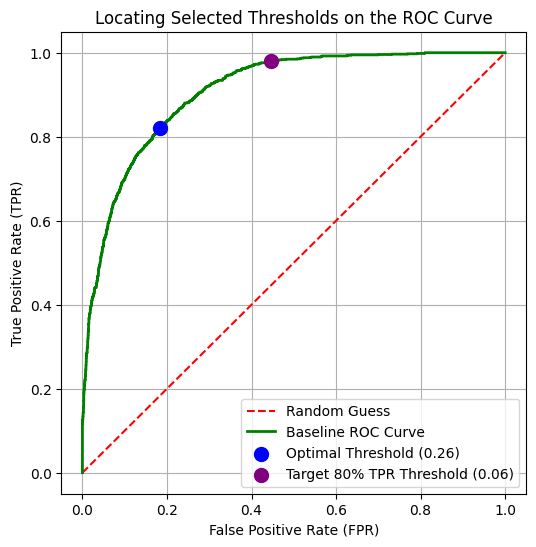

In [93]:
# 3. Visualizing these specific thresholds on the ROC Curve
plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Guess')
plt.plot(fpr_baseline_val, tpr_baseline_val, color='green', linewidth=2, label='Baseline ROC Curve')

# Highlight the optimal geometric threshold
plt.scatter(fpr_baseline_val[best_idx], tpr_baseline_val[best_idx], color='blue', s=100, zorder=5,
            label=f'Optimal Threshold ({best_threshold:.2f})')

# Highlight the 80% Recall threshold
plt.scatter(fpr_baseline_val[target_idx], tpr_baseline_val[target_idx], color='purple', s=100, zorder=5,
            label=f'Target 80% TPR Threshold ({target_threshold:.2f})')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Locating Selected Thresholds on the ROC Curve')
plt.legend()
plt.grid(True)
plt.show()